<div style="display:inline-block; padding:14px 30px; border-radius:40px 12px 40px 12px; background:#c7e9d0; color:#1e4d3a; font-family:'Segoe UI',sans-serif; font-size:1.6rem; font-weight:500; box-shadow:0 6px 18px rgba(0,0,0,0.06); border:1px solid rgba(255,255,255,0.4);">
    🌿 Fatemeh Habib Zadeh
</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

In [2]:
# داده‌های آموزش قبل از پیش‌پردازش
train_multi = pd.read_csv("auto-train-multi.csv")

# داده‌های آموزش بعد از پیش‌پردازش
train_preprocessed = pd.read_csv("auto-train-preprocessed.csv")

# داده‌های تست قبل از پیش‌پردازش
test_multi = pd.read_csv("auto-test-multi.csv")

# داده‌های تست بعد از پیش‌پردازش
test_preprocessed = pd.read_csv("auto-test-preprocessed.csv")

In [3]:
display(train_multi.head())

display(train_preprocessed.head())

display(test_multi.head())
display(test_preprocessed.head())


,cylinders,displacement,horsepower,weight,acceleration,year,mpg
0,0.2,0.059432,0.038043,0.051602,0.565476,0.416666,0.638298
1,1.0,0.728682,0.646739,0.754466,0.238095,0.166667,0.106383
2,0.2,0.124031,0.157609,0.154522,0.446429,0.250000,0.398936
3,0.0,0.005168,0.239130,0.144882,0.327381,0.250000,0.239362
4,1.0,0.857881,0.728261,0.739155,0.184524,0.583333,0.186170


,HorsePower,MPG
0,0.038043,0.638298
1,0.646739,0.106383
2,0.157609,0.398936
3,0.239130,0.239362
4,0.728261,0.186170


,cylinders,displacement,horsepower,weight,acceleration,year,mpg
0,1.0,0.813953,0.673913,0.552878,0.119048,0.00,0.159574
1,0.2,0.054264,0.135870,0.088460,0.357143,0.75,0.609043
2,1.0,0.857881,1.000000,0.755600,0.089286,0.25,0.186170
3,0.2,0.095607,0.130435,0.152254,0.410714,0.75,0.678191
4,0.6,0.341085,0.211957,0.276155,0.476190,0.00,0.319149


,HorsePower,MPG
0,0.673913,0.159574
1,0.135870,0.609043
2,1.000000,0.186170
3,0.130435,0.678191
4,0.211957,0.319149


In [4]:
print("Train Multi:", train_multi.shape)
print("Train Preprocessed:", train_preprocessed.shape)
print("Test Multi:", test_multi.shape)
print("Test Preprocessed:", test_preprocessed.shape)


Train Multi: (352, 7)
Train Preprocessed: (352, 2)
Test Multi: (40, 7)
Test Preprocessed: (40, 2)


In [5]:
print("Train Multi columns:")
print(train_multi.columns.tolist())

print("\nTrain Preprocessed columns:")
print(train_preprocessed.columns.tolist())

print("\nTest Multi columns:")
print(test_multi.columns.tolist())

print("\nTest Preprocessed columns:")
print(test_preprocessed.columns.tolist())


Train Multi columns:
['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year', 'mpg']

Train Preprocessed columns:
['HorsePower', 'MPG']

Test Multi columns:
['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year', 'mpg']

Test Preprocessed columns:
['HorsePower', 'MPG']


In [6]:
train_multi.info()
test_multi.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 352 entries, 0 to 351
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cylinders     352 non-null    float64
 1   displacement  352 non-null    float64
 2   horsepower    352 non-null    float64
 3   weight        352 non-null    float64
 4   acceleration  352 non-null    float64
 5   year          352 non-null    float64
 6   mpg           352 non-null    float64
dtypes: float64(7)
memory usage: 19.4 KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cylinders     40 non-null     float64
 1   displacement  40 non-null     float64
 2   horsepower    40 non-null     float64
 3   weight        40 non-null     float64
 4   acceleration  40 non-null     float64
 5   year          40 non-null     float64
 6   mpg           40 

In [7]:
print("missing values")

print("\nTrain Multi:")
print(train_multi.isnull().sum())

print("\nTest Multi:")
print(test_multi.isnull().sum())

print("\nTrain Preprocessed:")
print(train_preprocessed.isnull().sum())

print("\nTest Preprocessed:")
print(test_preprocessed.isnull().sum())


missing values

Train Multi:
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
year            0
mpg             0
dtype: int64

Test Multi:
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
year            0
mpg             0
dtype: int64

Train Preprocessed:
HorsePower    0
MPG           0
dtype: int64

Test Preprocessed:
HorsePower    0
MPG           0
dtype: int64


In [8]:
print("Train Multi duplicates:",train_multi.duplicated().sum())

print("Test Multi duplicates:",test_multi.duplicated().sum())


Train Multi duplicates: 0
Test Multi duplicates: 0


In [9]:
target_column = "mpg"

X_train_df = train_multi.drop(columns=[target_column])
y_train_series = train_multi[target_column]

X_test_df = test_multi.drop(columns=[target_column])
y_test_series = test_multi[target_column]

print("Features:")
print(X_train_df.columns.tolist())

print("\nLabel:")
print(target_column)


Features:
['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year']

Label:
mpg


In [10]:
display(train_multi.describe())


,cylinders,displacement,horsepower,weight,acceleration,year,mpg
count,352.000000,352.000000,352.000000,352.000000,352.000000,352.000000,352.000000
mean,0.488068,0.320410,0.311512,0.384101,0.452330,0.501420,0.385434
std,0.339725,0.264888,0.200227,0.241025,0.159629,0.303766,0.204968
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.200000,0.077519,0.161685,0.172030,0.349702,0.250000,0.226064
50%,0.200000,0.208010,0.250000,0.335838,0.446429,0.500000,0.372340
75%,1.000000,0.501292,0.429348,0.558194,0.537202,0.750000,0.531915
max,1.000000,1.000000,0.972826,1.000000,1.000000,1.000000,1.000000


In [11]:
X_train_df = X_train_df.apply(pd.to_numeric, errors="coerce")
X_test_df = X_test_df.apply(pd.to_numeric, errors="coerce")

y_train_series = pd.to_numeric(
    y_train_series,
    errors="coerce")

y_test_series = pd.to_numeric(
    y_test_series,
    errors="coerce"
)


In [12]:

train_valid = (X_train_df.notna().all(axis=1)& y_train_series.notna())

test_valid = (X_test_df.notna().all(axis=1)& y_test_series.notna())

X_train_df = X_train_df.loc[train_valid]
y_train_series = y_train_series.loc[train_valid]

X_test_df = X_test_df.loc[test_valid]
y_test_series = y_test_series.loc[test_valid]

print("تعداد داده‌های معتبر Train:", len(X_train_df))
print("تعداد داده‌های معتبر Test:", len(X_test_df))


تعداد داده‌های معتبر Train: 352
تعداد داده‌های معتبر Test: 40


In [13]:

X_train = X_train_df.to_numpy()
X_test = X_test_df.to_numpy()

y_train = y_train_series.to_numpy()
y_test = y_test_series.to_numpy()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


X_train shape: (352, 6)
y_train shape: (352,)
X_test shape: (40, 6)
y_test shape: (40,)


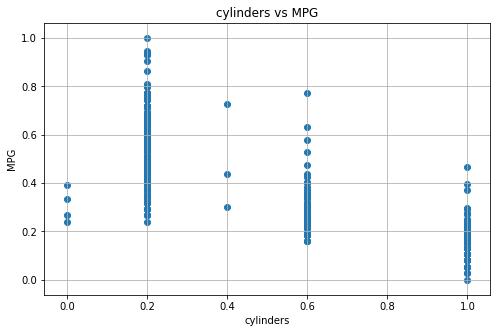

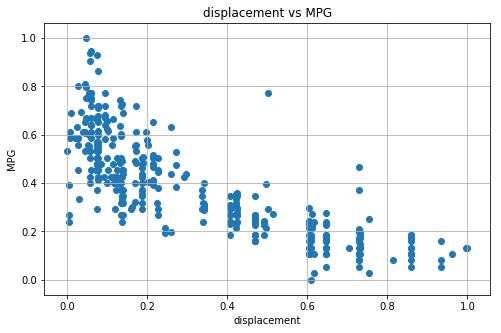

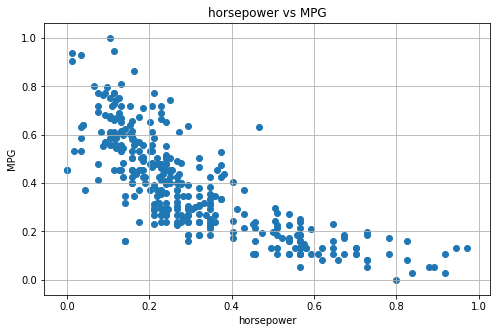

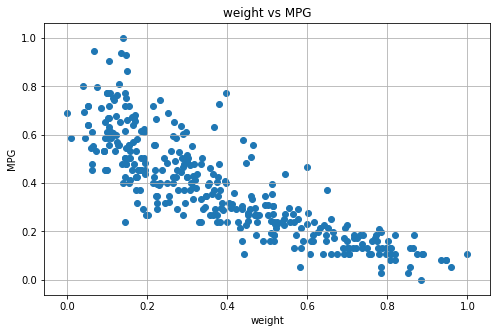

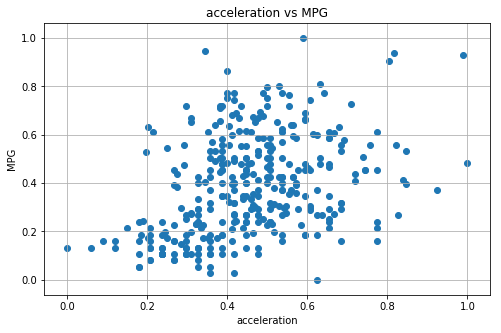

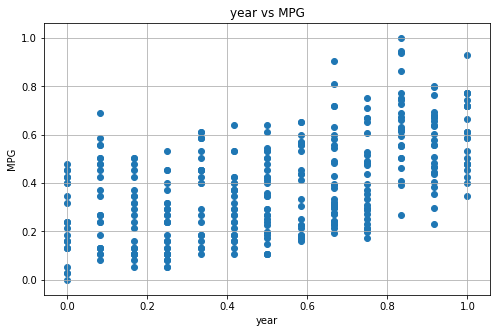

In [14]:
feature_names = X_train_df.columns

for feature_index, feature_name in enumerate(feature_names):

    plt.figure(figsize=(8, 5))

    plt.scatter(X_train[:, feature_index],y_train)

    plt.xlabel(feature_name)

    plt.ylabel("MPG")

    plt.title(f"{feature_name} vs MPG")

    plt.grid(True)

    plt.show()


<div style="display:inline-block; padding:14px 30px; border-radius:40px 12px 40px 12px; background:#b7d7f0; color:#1e3c5c; font-family:'Segoe UI',sans-serif; font-size:1.6rem; font-weight:500; box-shadow:0 6px 18px rgba(0,0,0,0.06); border:1px solid rgba(255,255,255,0.4);">
    ⭐ Fatemeh Ebrahimi
</div>

Creating Linear Regression class

In [16]:
class MyLinearRegression:

    def __init__(self) -> None:
        pass

    def fit(self,X,y):
        self.w = np.linalg.inv(X.T @ X) @ X.T @ y

    def predict(self,X):
        return X @ self.w

    def score(self,X,y):
        y_pred = X @ self.w
        return 1 - ( np.sum((y - y_pred)**2)/np.sum((y - y.mean())**2))

حالا در ادامه تست می کنم که کلاس رگرسیون خطی رو درست ساخته باشم :

Make the Pipeline

In [17]:
model = make_pipeline(
                                PolynomialFeatures(degree=2),
                                MyLinearRegression()
)

Show it's steps

In [18]:
model.steps

[('polynomialfeatures', PolynomialFeatures()),
 ('mylinearregression', <__main__.MyLinearRegression at 0x1e2fceda128>)]

Fit Pipeline

In [18]:
model.fit(X_train,y_train)

,steps,"[('polynomialfeatures', ...), ('mylinearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,degree,2
,interaction_only,False
,include_bias,True
,order,'C'


Get Scores

In [19]:
model.score(X_train, y_train)

e:\Anaconda\Lib\site-packages\sklearn\pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


np.float64(0.8793532803311099)

In [20]:
model.score(X_test, y_test)

e:\Anaconda\Lib\site-packages\sklearn\pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


np.float64(0.9310100095801119)

<div style="display:inline-block; padding:14px 30px; border-radius:40px 12px 40px 12px; background:#fad6c7; color:#6b3f2b; font-family:'Segoe UI',sans-serif; font-size:1.6rem; font-weight:500; box-shadow:0 6px 18px rgba(0,0,0,0.06); border:1px solid rgba(255,255,255,0.4);">
    🌸 Tina Hafezi
</div>

In [19]:
degrees = [2, 3, 4, 5, 6, 7]

train_scores = []
test_scores = []

### Pipeline

In [20]:
for degree in degrees:

    # ساخت پایپ لاین
    model = make_pipeline(
        PolynomialFeatures(degree=int(degree)),
        MyLinearRegression()
    )

    # آموزش مدل
    model.fit(X_train, y_train)

    # محاسبه Accuracy
    train_accuracy = model.score(X_train, y_train)
    test_accuracy = model.score(X_test, y_test)
    

    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

In [21]:
scores=np.stack([train_scores, test_scores, degrees])
print(pd.DataFrame(scores.T, columns=['train', 'test', 'degree']))

           train          test  degree
0       0.879353  9.310100e-01     2.0
1       0.924480  8.406937e-01     3.0
2       0.961493 -5.517882e+01     4.0
3     -39.364818 -2.266066e+07     5.0
4 -731605.756228 -7.802536e+12     6.0
5   -8908.634117 -2.761054e+12     7.0


### Visualize

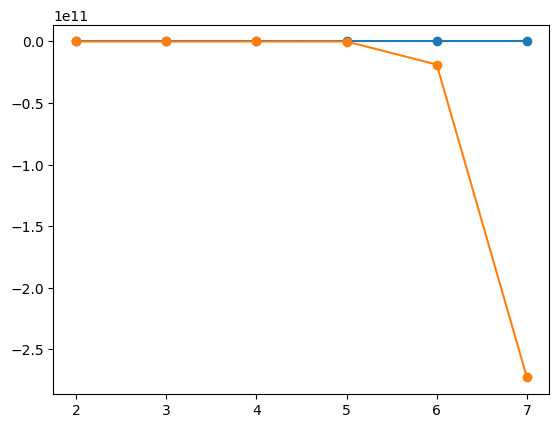

In [24]:
plt.plot(scores[2], scores[0],marker="o")
plt.plot(scores[2], scores[1],marker="o")
plt.show()

<div style="display:inline-block; padding:14px 30px; border-radius:40px 12px 40px 12px; background:#e1d4f0; color:#3d2b5c; font-family:'Segoe UI',sans-serif; font-size:1.6rem; font-weight:500; box-shadow:0 6px 18px rgba(0,0,0,0.06); border:1px solid rgba(255,255,255,0.4);">
    ✨ Faride Soltani Kia
</div>

Polynomial Degree Testing

In [25]:
degrees_test = [2, 3, 4, 5, 6, 7]

train_scores_test = []
test_scores_test = []

for degree in degrees_test:

    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    my_model = MyLinearRegression()

    my_model.fit(X_train_poly, y_train)

    train_r2 = my_model.score(X_train_poly, y_train)
    test_r2 = my_model.score(X_test_poly, y_test)

    train_scores_test.append(train_r2)
    test_scores_test.append(test_r2)



In [26]:
print(pd.DataFrame({
    "degree": degrees_test,
    "train_r2": train_scores_test,
    "test_r2": test_scores_test
}))

   degree      train_r2       test_r2
0       2      0.879353  9.310100e-01
1       3      0.924480  8.406937e-01
2       4      0.961493 -5.519174e+01
3       5    -25.113875 -2.508573e+07
4       6   -782.820567 -1.875182e+10
5       7 -36102.117272 -2.728865e+11


In [27]:
degrees_test = [2, 3, 4, 5]

results_test = []

for degree in degrees_test:

    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    my_model = MyLinearRegression()

    my_model.fit(X_train_poly, y_train)

    y_pred = my_model.predict(X_test_poly)

    r2 = my_model.score(X_test_poly, y_test)

    mse = np.mean((y_test - y_pred) ** 2)

    mae = np.mean(np.abs(y_test - y_pred))

    results_test.append([degree, r2, mse, mae])



In [28]:
print(pd.DataFrame(
    results_test,
    columns=["degree", "R2", "MSE", "MAE"]
))

   degree            R2           MSE         MAE
0       2  9.310100e-01  3.616018e-03    0.044777
1       3  8.406937e-01  8.349829e-03    0.062462
2       4 -5.519174e+01  2.945215e+00    0.483971
3       5 -2.508573e+07  1.314835e+06  271.417536


In [29]:
degree = 2

poly = PolynomialFeatures(degree=degree)

X_train_poly = poly.fit_transform(X_train)

my_model = MyLinearRegression()

my_model.fit(X_train_poly, y_train)

print("Weights:")
print(my_model.w)

Weights:
[ 0.70290732  0.09411102 -0.80671656  0.09326034 -0.53231213 -0.36523469
  0.00450337 -0.25576135 -0.36670148  0.66444181  0.32293698  0.37858442
 -0.24100867  0.43786051  0.57112765 -0.0402741  -0.16163842  0.72618263
 -0.64094806 -0.39199139 -0.55481498 -0.19587652  0.31526001  0.09057602
 -0.40582321  0.15579829  0.27410593  0.20400139]


Model Saving

In [33]:
import joblib

degree = 2

poly = PolynomialFeatures(degree=degree)

X_train_poly = poly.fit_transform(X_train)

best_model = MyLinearRegression()

best_model.fit(X_train_poly, y_train)

joblib.dump(best_model, "best_model.pkl")
joblib.dump(poly, "polynomial.pkl")

print("Model saved")

Model saved


Model Testing & Metrics

In [37]:
loaded_model = joblib.load("best_model.pkl")
loaded_poly = joblib.load("polynomial.pkl")

X_test_poly = loaded_poly.transform(X_test)

y_pred = loaded_model.predict(X_test_poly)

r2 = loaded_model.score(X_test_poly, y_test)

mse = np.mean((y_test - y_pred) ** 2)

mae = np.mean(np.abs(y_test - y_pred))


In [38]:
print("R2:", r2)
print("MSE:", mse)
print("MAE:", mae)

R2: 0.9310100095801119
MSE: 0.003616018384649317
MAE: 0.04477733465261684


In [39]:
print("Actual:")
print(y_test)

print("\nPredicted:")
print(y_pred)

Actual:
[0.15957448 0.6090426  0.18617022 0.6781915  0.31914896 0.6648936
 0.7446809  0.2393617  0.9148937  0.22606385 0.34574467 0.13297874
 0.84574467 0.25531918 0.106383   0.46542555 0.2393617  0.37234044
 0.34574467 0.15957448 0.07978725 0.13297874 0.21276596 0.13297874
 0.15957448 0.6223405  0.24468088 0.28989363 0.7180851  0.106383
 0.15957448 0.3324468  0.2393617  0.7180851  0.3989362  0.5053192
 0.26595747 0.5851064  0.6196808  0.3989362 ]

Predicted:
[0.17507264 0.67167298 0.09954272 0.61474744 0.28784193 0.70197371
 0.75604794 0.24855247 0.73246759 0.15655151 0.388291   0.20810013
 0.68861181 0.27361993 0.15610053 0.44342035 0.34471128 0.36719914
 0.41092747 0.20388615 0.07819662 0.11961555 0.18360441 0.17942079
 0.13044043 0.62868983 0.23228224 0.25765647 0.69297721 0.09893743
 0.18066855 0.39902377 0.20244339 0.66356906 0.39647709 0.5821898
 0.26755007 0.57884278 0.7160176  0.32759392]


Accuracy with Threshold (0.1)


In [36]:
correct = 0

for i in range(len(y_test)):
    if abs(y_pred[i] - y_test[i]) < 0.1:
        correct += 1

accuracy = correct / len(y_test)

print("Correct:", correct)
print("Total:", len(y_test))
print("Accuracy:", accuracy * 100, "%")

Correct: 37
Total: 40
Accuracy: 92.5 %


Accuracy with Threshold (0.5)


In [40]:
correct = 0

for i in range(len(y_test)):
    if abs(y_pred[i] - y_test[i]) < 0.5:
        correct += 1

accuracy = correct / len(y_test)

print("Correct:", correct)
print("Total:", len(y_test))
print("Accuracy:", accuracy * 100, "%")

Correct: 40
Total: 40
Accuracy: 100.0 %
